In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
base_path = "/content/drive/MyDrive/ML-Capstone-Project"
print(os.listdir(base_path))
print(os.listdir(f"{base_path}/data"))

['data', 'notebooks', 'results']
['housing.csv', 'clean_housing.csv']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [ ]:
base_path = "/content/drive/MyDrive/ML-Capstone-Project"
df = pd.read_csv(f"{base_path}/data/housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
print(df.info())
print("\n--- Missing values ---")
print(df.isnull().sum())
print("\n--- Describe ---")
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
None

--- Missing values ---
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_v

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


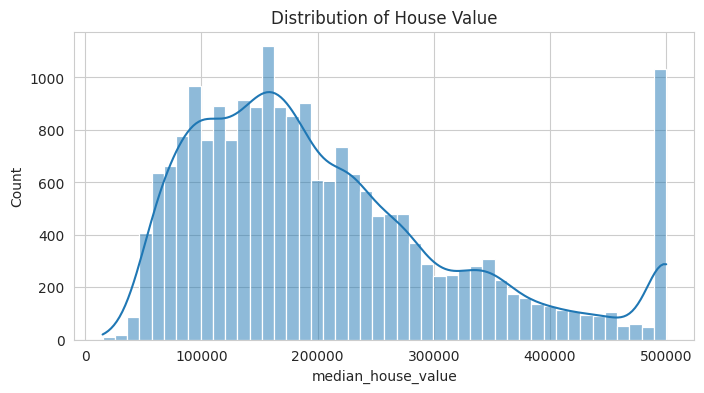

In [ ]:
plt.figure(figsize=(8,4))
sns.histplot(df["median_house_value"], kde=True)
plt.title("Distribution of House Value")
plt.show()

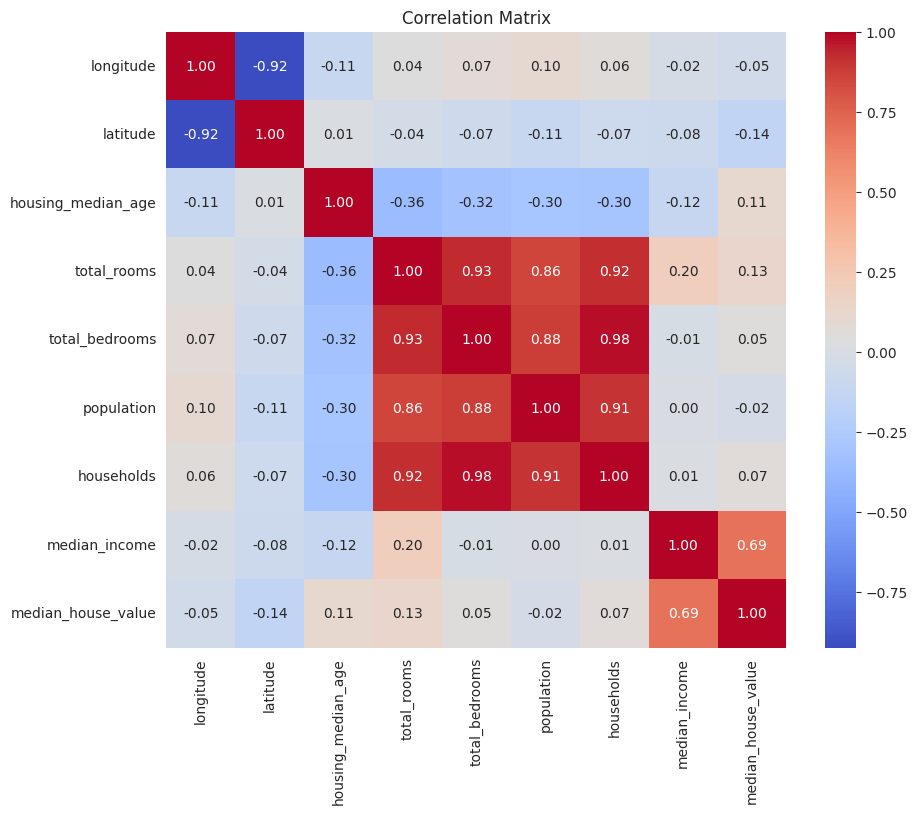

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

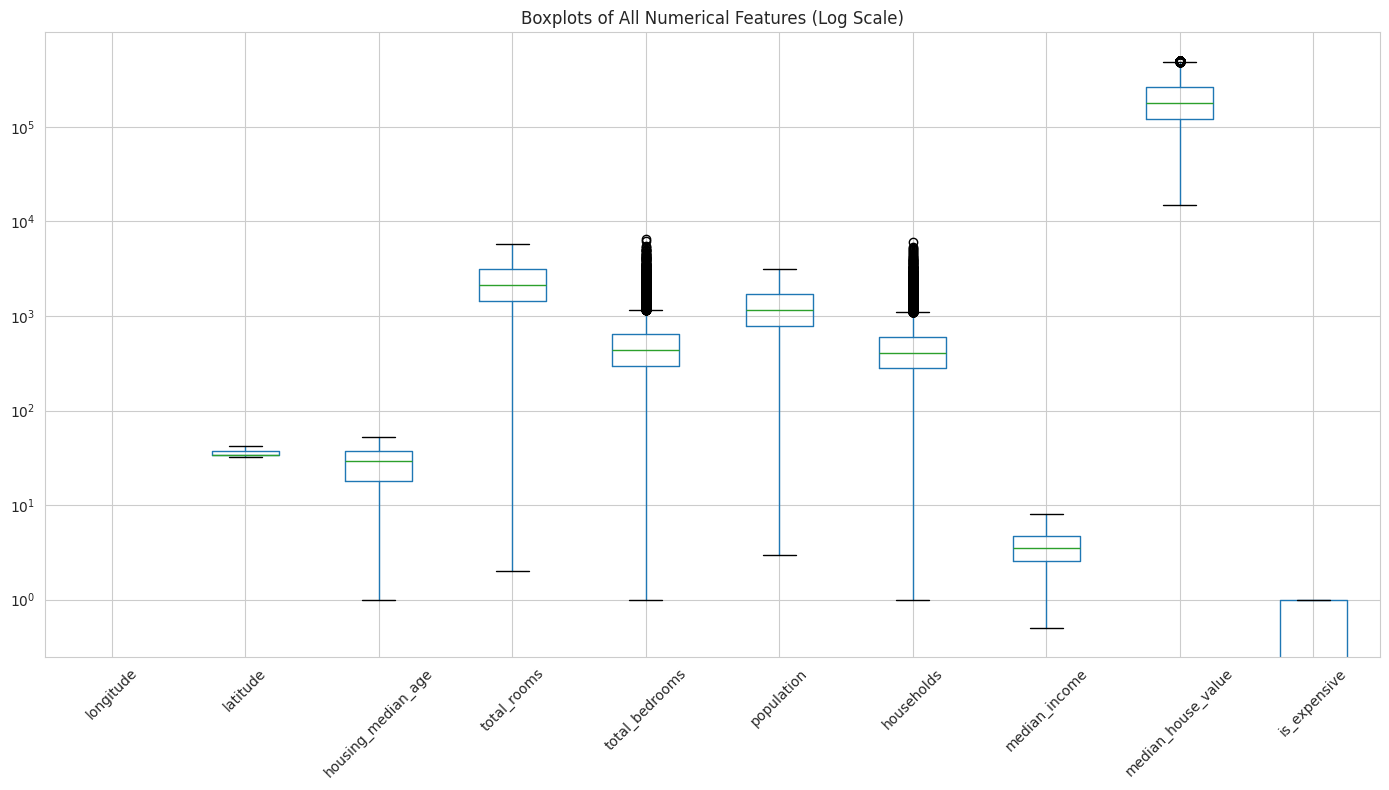

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

# بنرسم كل الأعمدة مع بعض في رسمة واحدة
df.select_dtypes(include='number').boxplot(rot=45)

# بنحول محور الـ Y لمقياس اللوغاريتم عشان كل الأعمدة تبان
plt.yscale('log')

plt.title('Boxplots of All Numerical Features (Log Scale)')
plt.tight_layout()
plt.show()

In [ ]:
# 1) Handle missing values
df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_bedrooms"].median())

# 2) Encoding (ocean_proximity عمود نصي)
df = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True)

# 3) Outlier capping (اختياري)
for col in ["median_income","total_rooms","population"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    df[col] = df[col].clip(q1 - 1.5*iqr, q3 + 1.5*iqr)

print("After cleaning:", df.shape)
print("Missing:", df.isnull().sum().sum())

After cleaning: (20640, 13)
Missing: 0


In [ ]:
median_val = df["median_house_value"].median()
df["is_expensive"] = (df["median_house_value"] > median_val).astype(int)
print(df["is_expensive"].value_counts())

is_expensive
0    10323
1    10317
Name: count, dtype: int64


In [ ]:
df.to_csv(f"{base_path}/data/clean_housing.csv", index=False)
print("Saved ✅")

Saved ✅
